In [10]:
%matplotlib inline

# Solution 6 (optional) — Misalignments and vertical emittance

Apply random quadrupole shifts to the DBA ring and compare the equilibrium emittances before and after the errors.

### Load the ring

In [11]:
import numpy as np
import xtrack as xt

ring = xt.load('ring_dba.json')

Loading line from dict:   0%|          | 0/208 [00:00<?, ?it/s]

Done loading line from dict.           


### Ideal-ring emittances

In [12]:
tw_ideal = ring.twiss4d(radiation_integrals=True)
print('Horizontal emittance:', tw_ideal.rad_int_eq_gemitt_x)  # m rad
print('Vertical emittance:', tw_ideal.rad_int_eq_gemitt_y)  # m rad

Horizontal emittance: 1.087131605183701e-08
Vertical emittance: 0.0


### Misalign the quadrupoles

Apply independent Gaussian horizontal and vertical shifts with 50 µm RMS to all quadrupoles.

In [13]:
table = ring.get_table()
table_quads = table.rows.match(element_type='Quadrupole')
quad_names = table_quads.name

rng = np.random.default_rng(2026)
sigma_shift = 50e-6  # m
shift_x = rng.normal(scale=sigma_shift, size=len(quad_names))
shift_y = rng.normal(scale=sigma_shift, size=len(quad_names))

for name, shx, shy in zip(quad_names, shift_x, shift_y):
    ring[name].shift_x = shx
    ring[name].shift_y = shy

### Recompute the optics and radiation integrals

In [14]:
tw_errors = ring.twiss4d(radiation_integrals=True)

### Horizontal equilibrium emittance

In [15]:
print('Ideal:', tw_ideal.rad_int_eq_gemitt_x)  # m rad
print('Misaligned:', tw_errors.rad_int_eq_gemitt_x)  # m rad

Ideal: 1.087131605183701e-08
Misaligned: 1.0796803347681034e-08


### Vertical equilibrium emittance

In [16]:
print('Ideal:', tw_ideal.rad_int_eq_gemitt_y)  # m rad
print('Misaligned:', tw_errors.rad_int_eq_gemitt_y)  # m rad

Ideal: 0.0
Misaligned: 1.170924830927487e-11


### Why do misalignments introduce vertical emittance?

Neglecting transverse coupling, the radiation-integral estimate of the vertical equilibrium geometric emittance is

$$
\varepsilon_y = \frac{55\sqrt{3}}{96}\frac{\hbar\gamma^2}{m_0 c}\frac{I_{5y}}{I_2-I_{4y}},
$$

where:

$$
\mathcal{H}_y=\frac{1+\alpha_y^2}{\beta_y}D_y^2+2\alpha_y D_y D'_y+\beta_y(D'_y)^2,
\qquad I_{5y}=\oint\frac{\mathcal{H}_y}{|\rho|^3}\,ds,
\qquad I_2=\oint\frac{ds}{\rho^2}.
$$

Here $m_0$ is the particle rest mass and $\gamma$ is the Lorentz factor.

### Plot vertical closed orbit and vertical dispersion

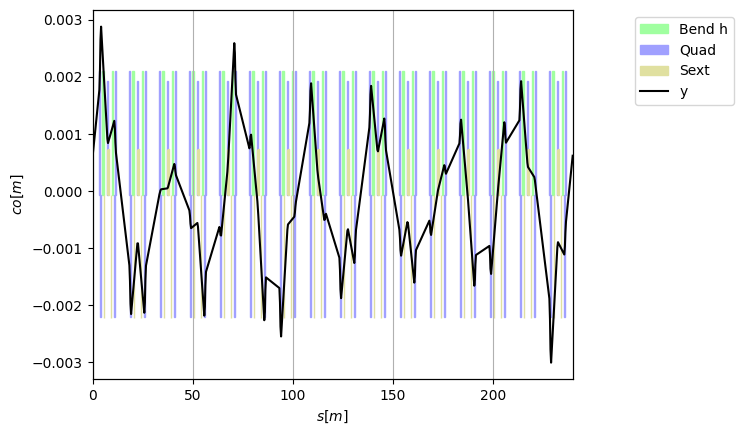

In [8]:
tw_errors.plot('y')

### Vertical dispersion

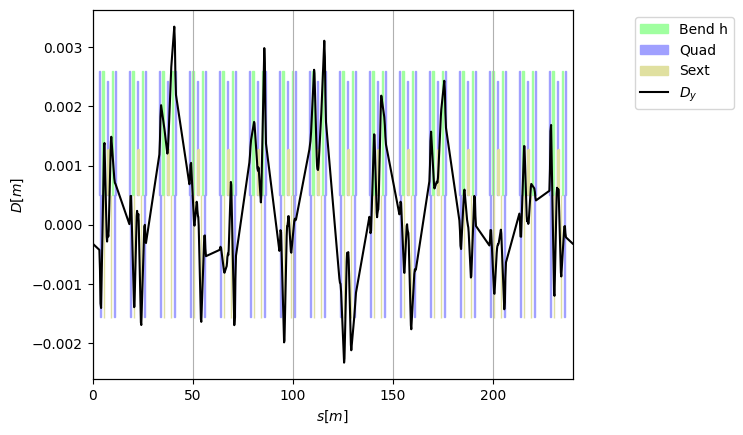

In [9]:
tw_errors.plot('dy')